/tmp/ipykernel_99957/2435039797.py:31: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Saved: QSVM_full_circuit.png


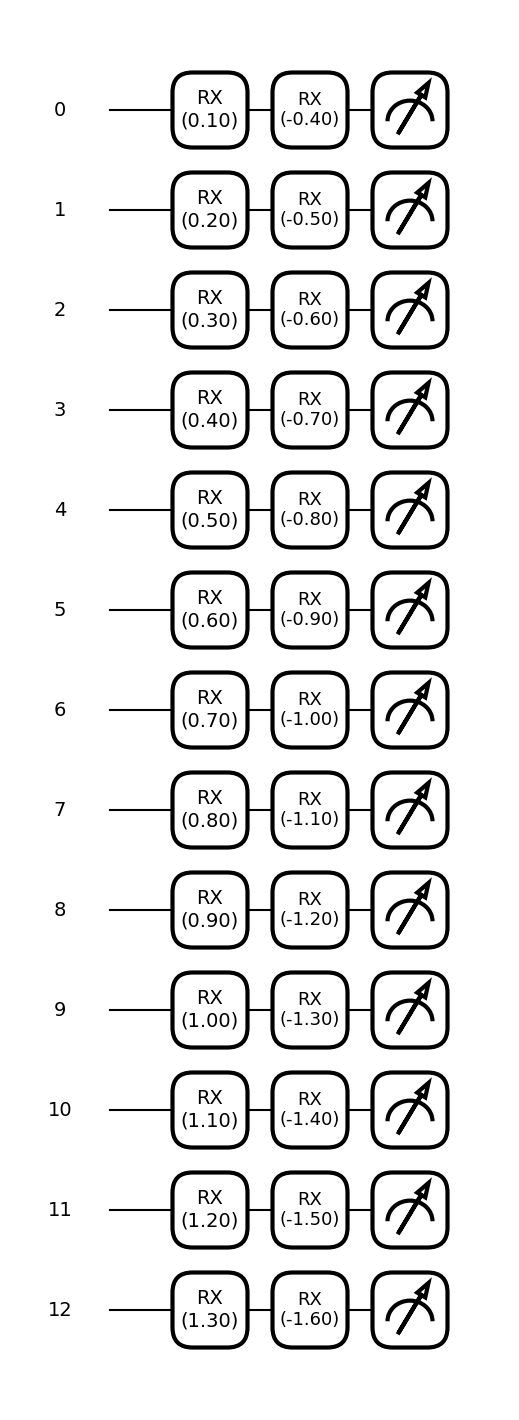

In [5]:
import pennylane as qml
from pennylane import numpy as np
import matplotlib.pyplot as plt

NUM_FEATURES = 13

dev = qml.device("default.qubit", wires=NUM_FEATURES)

# =======================================================
# MANUAL FULL QSVM CIRCUIT (EVERY RX GATE SHOWN)
# =======================================================
@qml.qnode(dev)
def qsvm_kernel_manual(x1, x2):

    # First embedding
    for i in range(NUM_FEATURES):
        qml.RX(x1[i], wires=i)

    # Adjoint embedding
    for i in range(NUM_FEATURES):
        qml.RX(-x2[i], wires=i)

    return qml.state()  # no measurement collapsing

# =======================================================
# DRAW FUNCTION THAT NEVER COLLAPSES
# =======================================================
def draw_circuit(func, filename, *args):
    fig, ax = qml.draw_mpl(func, decimals=2, wire_order=range(NUM_FEATURES))(*args)
    # fig.set_size_inches(14, 4)
    fig.tight_layout()
    fig.savefig(filename, dpi=400, bbox_inches="tight")
    print("Saved:", filename)

# Example data
x1 = np.linspace(0.1, 1.3, NUM_FEATURES)
x2 = np.linspace(0.4, 1.6, NUM_FEATURES)

draw_circuit(qsvm_kernel_manual, "QSVM_full_circuit.png", x1, x2)


Saved: QNN_full_circuit.png




In [7]:
def draw_circuit(func, filename, *args):
    fig, ax = qml.draw_mpl(func, decimals=2, wire_order=range(NUM_FEATURES))(*args)
    # fig.set_size_inches(14, 4)
    # fig.tight_layout()
    fig.savefig(filename, dpi=400, bbox_inches="tight")
    print("Saved:", filename)
#=======================================================
# FULLY MANUAL STRONGLY ENTANGLING LAYERS
# =======================================================
def strongly_entangling_layers_manual(weights):
    L, Q, _ = weights.shape
    for layer in range(L):

        # Single-qubit rotations
        for i in range(Q):
            a, b, c = weights[layer, i]
            qml.Rot(a, b, c, wires=i)

        # CNOT ring
        for i in range(Q - 1):
            qml.CNOT(wires=[i, i+1])
        qml.CNOT(wires=[Q-1, 0])

# =======================================================
# FULL QNN CIRCUIT MANUAL
# =======================================================
@qml.qnode(dev)
def qnn_manual(x, w):

    # Input encoding
    for i in range(NUM_FEATURES):
        qml.RX(x[i], wires=i)

    # Full entangling layers (manual)
    strongly_entangling_layers_manual(w)

    # No measurement (we want full circuit)
    return qml.state()

# =======================================================
# DRAW QNN
# =======================================================

w = np.random.random((7, NUM_FEATURES, 3))
x = np.linspace(0.1, 1.2, NUM_FEATURES)

draw_circuit(qnn_manual, "QNN_full_circuit.png", x, w)


NameError: name 'qnode' is not defined



In [ ]:
import matplotlib.pyplot as plt
import pennylane as qml

# --- your device + qnode definition here ---
# Example:
# n_qubits = 13
# dev = qml.device("default.qubit", wires=n_qubits)
#
# @qml.qnode(dev)
# def qnode(weights):
#     for layer in range(weights.shape[0]):
#         for i in range(n_qubits):
#             qml.Rot(*weights[layer, i], wires=i)
#         for i in range(n_qubits - 1):
#             qml.CNOT(wires=[i, i+1])
#     return qml.state()

# ---- DRAW HIGH-RES ----

plt.rcParams.update({'font.size': 16})

fig, ax = plt.subplots(
    figsize=(48, 14),  # Wider than the SEL circuit because Rot+CNOT ladders spread more
    dpi=300
)

qml.draw_mpl(qnode)(ax=ax)

plt.tight_layout()
plt.savefig("rot_cnot_ladder_highres.png", dpi=300, bbox_inches="tight")
plt.show()
